# Hoja de trabajo 7 

### Análisis Estadístico Aplicado a la Resistencia del Concreto

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

### 1. Descripción del conjunto de datos

#### Código de soporte

In [23]:
# Carga de datos
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/concrete/compressive/Concrete_Data.xls"
columnas = ['Cement', 'Slag', 'FlyAsh', 'Water', 'Superplasticizer', 'CoarseAgg', 'FineAgg', 'Age', 'Strength']
df = pd.read_excel(url, names=columnas)
df.head()

,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAgg,FineAgg,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


### Parte A: Análisis descriptivo

In [24]:
variables = ['Cement', 'Water']

resumen = pd.DataFrame()
resumen['Media'] = df[variables].mean()
resumen['Mediana'] = df[variables].median()
resumen['Desviacion estandar'] = df[variables].std()
resumen['Coef Variacion %'] = (df[variables].std() / df[variables].mean()) * 100
print(resumen)

             Media  Mediana  Desviacion estandar  Coef Variacion %
Cement  281.165631    272.9           104.507142         37.169245
Water   181.566359    185.0            21.355567         11.761852


¿Cuál de los dos presenta mayor variabilidad en los diseños de mezcla analizados? ¿Qué implicaciones constructivas tiene un control deficiente en la dosificación del agua?

- El agua presenta un mayor coeficiente de variación que el cemento, por lo que existe un control irregular en la dosificación.

Implicación: Un control deficiente altera la relación agua/cemento, reduciendo drásticamente la resistencia mecánica y afectando la eficiencia del mismo

### Parte B: Gráficos estadísticos

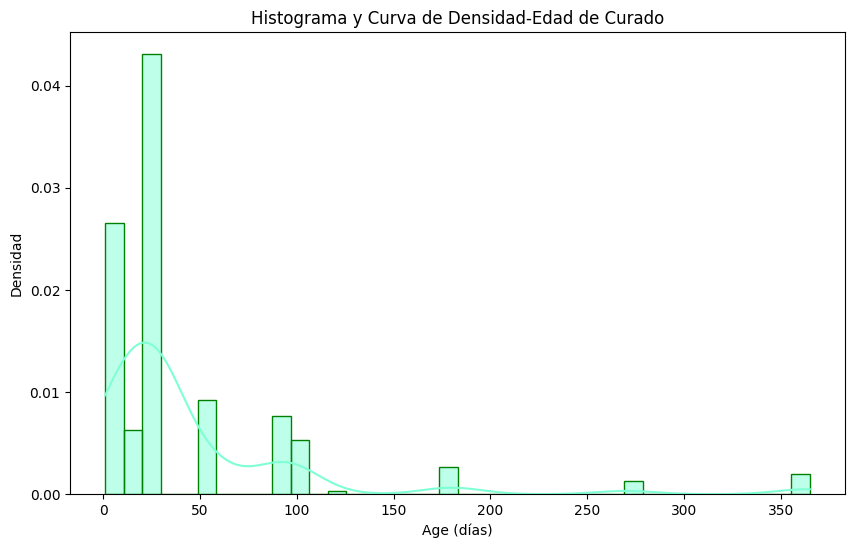

Sesgo: 3.26917740063459
Curtosis: 12.168988978672088


In [25]:
#Histograma
plt.figure(figsize=(10, 6))
sns.histplot(df['Age'], kde=True, stat="density", color="Aquamarine", edgecolor="green")
plt.title('Histograma y Curva de Densidad-Edad de Curado')
plt.xlabel('Age (días)')
plt.ylabel('Densidad')
plt.show()

print("Sesgo:", df['Age'].skew())
print("Curtosis:", df['Age'].kurtosis())

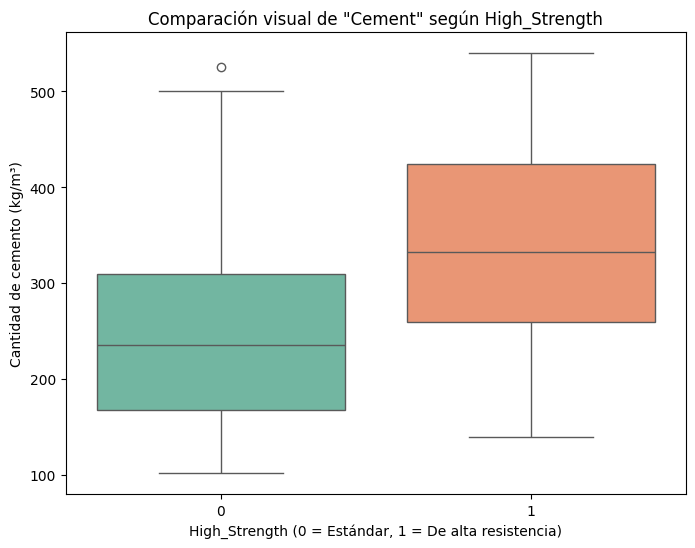

In [26]:
#Box plot
#definimos el umbral para saber si se califica con High_Strength o no
df['High_Strength'] = (df['Strength'] >= 40).astype(int)

plt.figure(figsize=(8, 6))
sns.boxplot(
    x='High_Strength', 
    y='Cement', 
    hue='High_Strength', 
    data=df, 
    palette='Set2', 
    legend=False
)

plt.title('Comparación visual de "Cement" según High_Strength')
plt.xlabel('High_Strength (0 = Estándar, 1 = De alta resistencia)')
plt.ylabel('Cantidad de cemento (kg/m³)')
plt.show()

Visualmente, ¿se observa una diferencia notable en los cuartiles de la cantidad de cemento entre los concretos de resistencia estándar y los de alta resistencia? ¿Existen valores atípicos (outliers)?

- Diferencia n los cuartiles: Se observa una diferencia notable, la mediana del gupo de "alta resistencia" están desplazadas hacia valores más altos en comparación con el grupo de "resistencia estandar". Es decir que en la práctica alcanzar niveles superiores de resistencia mecánica exige una mayor dotación base de cemento por metro cúbico en la mezcla.
- Si se identifican valores atípicos, estos ouliners representan diseños de mezcla atípicos o no usuales. Por ejemplo, mezclas donde se logró alta resistencia con poco cemento mediante el uso intensivo de aditivos superplastificantes.


### Parte C: Regresión logística

In [27]:
#Definición de variables independientes(x) e independiente(y)
X = df[['Cement', 'Water', 'Age']]
y = df['High_Strength']

#Agregar la constante(intercepto)
X_sm = sm.add_constant(X)
#Ajustar el modelo de regresión logística
modelo = sm.Logit(y, X_sm).fit()

#Tabla de coeficientes 
print(modelo.summary())

# Calcular los Odds Ratios
odds_ratios = np.exp(modelo.params)
print("\nODDS RATIOS")
print(odds_ratios)

Optimization terminated successfully.
         Current function value: 0.456104
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:          High_Strength   No. Observations:                 1030
Model:                          Logit   Df Residuals:                     1026
Method:                           MLE   Df Model:                            3
Date:                Wed, 04 Nov 2026   Pseudo R-squ.:                  0.3067
Time:                        22:13:40   Log-Likelihood:                -469.79
converged:                       True   LL-Null:                       -677.60
Covariance Type:            nonrobust   LLR p-value:                 9.153e-90
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.2898      0.752      4.374      0.000       1.816       4.764
Cement         0.0102      0.

¿Cómo varían las probabilidades de obtener un concreto de alta resistencia?

- Por cada incremento de 1 $\text{kg/m}^3$ en la cantidad de cemento, la ventaja o probabilidad relativa de que la mezcla alcance una alta resistencia aumenta en un factor igual al OR. Esto confirma que añadir cemento incrementa las probabilidades de lograr un concreto de alta resistencia. 

Explique detalladamente, basándose en los principios de la relación agua/cemento (Ley de Abrams), por qué el modelo arroja ese signo analítico.

- El signo asociado a la variable del agua es negativo. La ley de Abrams establece empíricamente que la resistencia mecánica a la compresión del concreto es una función inversamente proporcional a la relación agua/cemento. A medida que se incrementa la cantidad de agua a la mezcla manteniendo la dosis de cemento fija, la relación aumenta. El excedente de agua no reacciona quimicamente por ende deja poros en la mezcla. Por lo tanto, un mayor contenido de agua aumenta la porosidad final de la mezcla y reduce la resistencia mecánica de la misma, esto se refleja con el coeficiente negativo.

En otras palabras, nos indica que a mayor cantidad de agua, menor es la probabilidad de obtener un concreto de alta resistencia.